# Did Your Savings Beat Inflation? Nigeria, 2006–2026

Nigerians save in naira bank accounts, fixed deposits, Treasury bills or US dollars.
Inflation often ran far above the interest banks paid, so money in the bank may have
grown in naira while buying less and less.

**Goal:** measure how each common way of saving performed **after inflation**, using
monthly data from the Central Bank of Nigeria (CBN).

> **This is analysis, not financial advice.** Past returns do not predict future returns.

## 1. Setup

**Question:** Do we have the right tools loaded and working?

We use four packages:
- `pandas` for tables of data
- `matplotlib` for charts
- `requests` to download data from the CBN website
- `pathlib` (built into Python) for file and folder paths

In [1]:
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import requests

# Folders for the saved data snapshot and the README charts
DATA_DIR = Path("data")
IMAGES_DIR = Path("images")
DATA_DIR.mkdir(exist_ok=True)
IMAGES_DIR.mkdir(exist_ok=True)

print("Python:    ", sys.version.split()[0])
print("pandas:    ", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("requests:  ", requests.__version__)

Python:     3.15.0
pandas:     3.1.0
matplotlib: 3.11.2
requests:   2.34.2


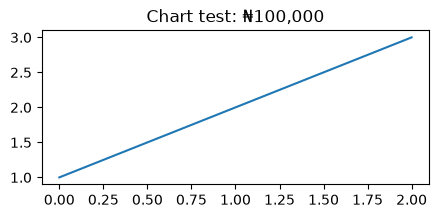

In [2]:
# Quick chart test: matplotlib had font problems on Python 3.15 in an earlier project.
# If this draws a line with the title below, charts work.
fig, ax = plt.subplots(figsize=(5, 2))
ax.plot([1, 2, 3])
ax.set_title("Chart test: ₦100,000")
plt.show()

**Finding:** All packages load and matplotlib can draw a chart, including the naira sign (₦).
The environment is ready for the data pull.

## 2. Data pull from the CBN

**Question:** Can we download 20 years of Nigerian interest rates, inflation and the
naira–dollar exchange rate, and combine them into one clean monthly table?

The CBN website gets its numbers from three **JSON feeds** (an API: a web address that
returns data for programs instead of a page for people):

| Feed | What it holds |
|---|---|
| `GetAllMoneyMarketIndicators` | Monthly interest rates from Jan 2006: savings, fixed deposits, Treasury bills, MPR… |
| `GetAllInflationRates` | Monthly year-on-year inflation from Jan 2003 |
| `GetAllExchangeRates` | Daily official exchange rates for many currencies |

These feeds are **undocumented**, so they could change or disappear. That's why, every
time the download works, we save a **CSV snapshot**. If the download fails, the notebook
loads the snapshot instead, so it still runs offline.

In [ ]:
# The CBN data feeds (undocumented, so they could change without notice)
BASE_URL = "https://www.cbn.gov.ng/api/"
FEEDS = {
    "money_market": "GetAllMoneyMarketIndicators",
    "inflation": "GetAllInflationRates",
    "exchange_rates": "GetAllExchangeRates",
}

# Some servers refuse requests that don't look like they come from a web browser
HEADERS = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                  "(KHTML, like Gecko) Chrome/130.0 Safari/537.36"
}

SNAPSHOT_PATH = DATA_DIR / "cbn_savings_data.csv"


def fetch_feed(feed_name):
    """Download one CBN feed and return it as a DataFrame (every value is still text)."""
    response = requests.get(BASE_URL + feed_name, headers=HEADERS, timeout=120)
    response.raise_for_status()  # stop with an error if the server says no (e.g. 404 or 500)
    return pd.DataFrame(response.json())

### Cleaning each feed

The feeds send every number as **text** (for example `"5.36"`), so we convert them with
`pd.to_numeric`. Using `errors="coerce"` turns anything that isn't a number, such as a
blank `""`, into `NaN` (missing) instead of crashing.

The feeds also store dates as two columns, `tyear` and `tmonth`. We combine them into
one `month` date (the 1st of each month), so the three tables can be lined up.

In [ ]:
# The interest rate columns in the money market feed (all in % per year)
RATE_COLUMNS = [
    "savingsDeposit", "oneMonthDeposit", "threeMonthsDeposit", "sixMonthsDeposit",
    "twelveMonthsDeposit", "treasuryBill", "mpr", "mrr",
    "interBankCallRate", "primeLending", "maxLending",
]


def add_month_column(df):
    """Combine the tyear and tmonth columns into one date: the 1st of each month."""
    df["month"] = pd.to_datetime({"year": df["tyear"], "month": df["tmonth"], "day": 1})
    return df


def clean_money_market(raw):
    df = add_month_column(raw.copy())
    for col in RATE_COLUMNS:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    # The feed is newest-first; sort it oldest-first
    return df[["month"] + RATE_COLUMNS].sort_values("month")


def clean_inflation(raw):
    df = add_month_column(raw.copy())
    # "YearOn" = year-on-year: how much prices rose compared with the same month last year
    df["inflation"] = pd.to_numeric(df["allItemsYearOn"], errors="coerce")
    df["food_inflation"] = pd.to_numeric(df["foodYearOn"], errors="coerce")
    return df[["month", "inflation", "food_inflation"]].sort_values("month")

The exchange rate feed needs more work:
- It holds **every currency**, and some names have stray spaces or tabs
  (`"US DOLLAR"` and `"US DOLLAR "` both appear). We strip those before picking the dollar.
- It is **daily**, but the other feeds are monthly. We take the **average rate of each month**.
- A few days appear twice, so we keep one row per day.

`centralrate` is the CBN's official rate: how many naira one US dollar cost.

In [ ]:
def clean_usd(raw):
    df = raw.copy()
    df["currency"] = df["currency"].str.strip()  # remove stray spaces and tabs
    usd = df[df["currency"] == "US DOLLAR"].copy()

    usd["date"] = pd.to_datetime(usd["ratedate"])
    usd["usd_ngn"] = pd.to_numeric(usd["centralrate"], errors="coerce")
    usd = usd.drop_duplicates(subset="date")  # one row per day

    # resample("MS") groups the days into months, dated at the Month Start (the 1st)
    monthly = usd.set_index("date")["usd_ngn"].resample("MS").mean()
    return monthly.reset_index().rename(columns={"date": "month"})

### Download, combine, save (or fall back to the snapshot)

We **merge** the three tables on `month`. The money market table goes first and decides
which months we keep (Jan 2006 onwards), because without interest rates there is nothing
to compare.

`try` / `except` means: *try the download; if a network error happens, run the
`except` part instead.* We only catch download errors (`RequestException`) and broken
JSON (`ValueError`), so a mistake in our own code still shows up as an error.

In [ ]:
try:
    print("Downloading CBN feeds (the exchange rate feed is about 8 MB)...")
    money_market = clean_money_market(fetch_feed(FEEDS["money_market"]))
    inflation = clean_inflation(fetch_feed(FEEDS["inflation"]))
    usd = clean_usd(fetch_feed(FEEDS["exchange_rates"]))

    data = (
        money_market
        .merge(inflation, on="month", how="left")
        .merge(usd, on="month", how="left")
    )
    data.to_csv(SNAPSHOT_PATH, index=False)
    print(f"Live data downloaded. Snapshot saved to {SNAPSHOT_PATH}")

except (requests.RequestException, ValueError) as error:
    print(f"Download failed: {error}")
    print(f"Using the saved snapshot instead: {SNAPSHOT_PATH}")
    data = pd.read_csv(SNAPSHOT_PATH, parse_dates=["month"])

In [ ]:
print("Rows (months):", len(data))
print("From", data["month"].min().date(), "to", data["month"].max().date())
data.head()

In [ ]:
data.tail()

**Finding:** We have one clean monthly table: **249 months, January 2006 to September 2026**,
with every rate stored as a number. A first look already tells the story:

- In January 2006 a savings account paid **4.50%** while inflation was **10.7%**.
- One US dollar cost **₦128.50** in January 2006 and about **₦1,327** in September 2026,
  roughly **10 times** as many naira.

A few things to check in the Data Quality section:
- `mpr` shows **0.0** for early 2006. The MPR didn't exist yet, so that means *missing*, not 0%.
- `mrr` is missing for most months, because the MPR replaced it.
- `interBankCallRate` has 5 missing months (we don't use it for savings).
- Some rates jump around a lot (e.g. Treasury bills fell from 13.68% to 6.65% in early 2006,
  and the savings rate fell from 7.46% to 5.36% in the latest month). We'll check whether those are real.

The snapshot is saved in `data/cbn_savings_data.csv`, so the notebook still runs offline.